# Geo-vektor — Hotspot (KDE + Moran's I + LISA)
**Kapan dipakai:** ada titik kejadian (gempa, kebakaran, kriminalitas, kasus penyakit, laporan
warga) dan diminta menunjukkan "titik panas": di mana kejadian menggerombol lebih dari kebetulan.

**Idenya:**
- **KDE**: tiap titik jadi bukit kecil, bukit dijumlahkan → peta kepadatan halus.
- Wilayah dibagi jadi sel grid, titik dihitung per sel.
- **Global Moran's I**: apakah sel padat cenderung bertetangga dengan sel padat?
- **LISA**: sel mana yang hotspot (HH), coldspot (LL), atau pencilan (HL/LH).

**Langkah:**
1. Titik → koordinat meter (`to_crs`), lalu KDE.
2. Grid sel, hitung titik per sel (`sjoin`).
3. Moran's I, LISA, peta, submission per sel.

**Data demo:** 10.010 gempa M ≥ 4.5 di sekitar Indonesia 2015–2025 (USGS) + batas provinsi.

In [1]:
import esda
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from libpysal import weights
from shapely.geometry import box
from sklearn.neighbors import KernelDensity

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/geo"   # GANTI saat lomba
POINTS_CSV = f"{DATA_FOLDER}/gempa_indonesia_2015_2025.csv"
REGIONS_FILE = f"{DATA_FOLDER}/indonesia_provinsi.geojson"

LON_COL = "longitude"
LAT_COL = "latitude"
CRS_METER = "EPSG:3395"   # sistem koordinat dalam meter (Mercator dunia, cukup di sekitar ekuator)
CELL_SIZE = 100_000       # sisi sel grid (meter) untuk Moran/LISA
BANDWIDTH_KM = 50         # kehalusan KDE: makin besar makin rata
KDE_STEP_KM = 20          # jarak antar titik evaluasi KDE
ALPHA = 0.05              # batas p-value LISA
SEED = 42

## Baca data

In [3]:
events = pd.read_csv(POINTS_CSV)
regions = gpd.read_file(REGIONS_FILE)
regions = regions.to_crs(CRS_METER)
geometry = gpd.points_from_xy(events[LON_COL], events[LAT_COL])
points = gpd.GeoDataFrame(events, geometry=geometry, crs="EPSG:4326")
points = points.to_crs(CRS_METER)       # derajat → meter, supaya jarak dan luas bermakna
print(len(points), "titik |", len(regions), "wilayah")
points.head(3)

10010 titik | 34 wilayah


,time,latitude,longitude,depth,mag,place,geometry
0,2025-12-30T22:36:09.826Z,3.0448,128.8654,10.000,4.5,"173 km NNE of Tobelo, Indonesia",POINT (14345230.709 336837.254)
1,2025-12-30T20:55:06.344Z,1.1328,123.3440,10.000,4.5,"72 km NNE of Gorontalo, Indonesia",POINT (13730591.272 125266.81)
2,2025-12-30T16:45:05.128Z,6.2037,126.8425,80.527,4.5,"75 km ESE of Pondaguitan, Philippines",POINT (14120042.511 687331.868)


## Langkah 1 — KDE, peta kepadatan titik
Setiap titik "menyebar" sebagai bukit Gauss selebar `BANDWIDTH_KM`, bukit dijumlahkan.

grid KDE: (100, 268)


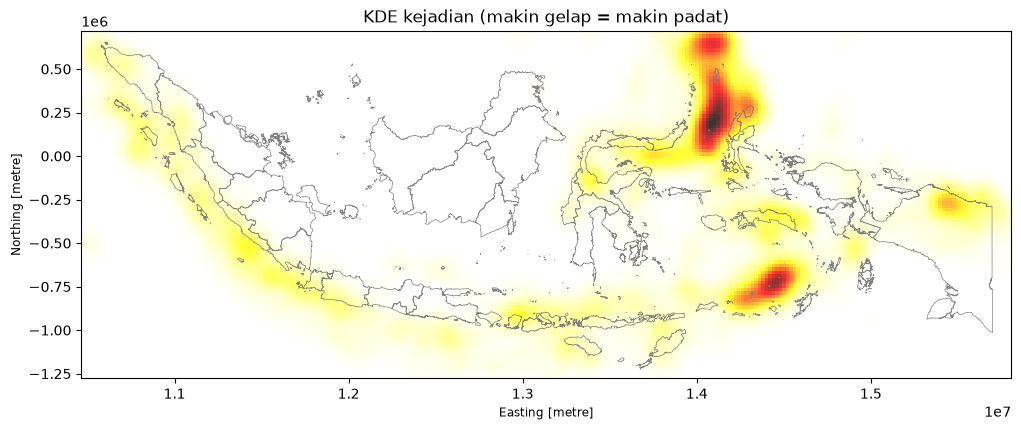

In [4]:
coordinates_km = np.column_stack([points.geometry.x, points.geometry.y]) / 1000
x_min, y_min = coordinates_km.min(axis=0)
x_max, y_max = coordinates_km.max(axis=0)
axis_x = np.arange(x_min, x_max, KDE_STEP_KM)
axis_y = np.arange(y_min, y_max, KDE_STEP_KM)
grid_x, grid_y = np.meshgrid(axis_x, axis_y)
grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])

kde = KernelDensity(bandwidth=BANDWIDTH_KM, kernel="gaussian")
kde.fit(coordinates_km)
density = np.exp(kde.score_samples(grid_points))
density = density.reshape(grid_x.shape)
print("grid KDE:", density.shape)

fig, ax = plt.subplots(figsize=(12, 5))
regions.boundary.plot(ax=ax, color="gray", linewidth=0.5)
ax.imshow(density, origin="lower", cmap="hot_r", alpha=0.8,
          extent=[x_min * 1000, x_max * 1000, y_min * 1000, y_max * 1000])
ax.set_title("KDE kejadian (makin gelap = makin padat)")
plt.show()

## Langkah 2 — grid sel dan hitung titik per sel
`sjoin` (point-in-polygon) memasangkan tiap titik ke sel yang memuatnya.

In [5]:
left = points.geometry.x.min()
right = points.geometry.x.max()
bottom = points.geometry.y.min()
top = points.geometry.y.max()
cells = []
for cell_y in np.arange(bottom, top, CELL_SIZE):
    for cell_x in np.arange(left, right, CELL_SIZE):
        cells.append(box(cell_x, cell_y, cell_x + CELL_SIZE, cell_y + CELL_SIZE))
grid = gpd.GeoDataFrame(geometry=cells, crs=CRS_METER)
grid["cell_id"] = range(len(cells))

points_in_cell = gpd.sjoin(points, grid, predicate="within", how="inner")
counts = points_in_cell.groupby("cell_id").size()
grid["count"] = grid["cell_id"].map(counts)
grid["count"] = grid["count"].fillna(0)
print(len(grid), "sel, berisi titik:", (grid["count"] > 0).sum())

1080 sel, berisi titik: 505


## Langkah 3a — Global Moran's I: apakah kejadian mengelompok?
Tetangga = sel yang bersentuhan (Queen), bobot dinormalkan per baris.
I ≈ 0 berarti acak, I > 0 berarti mengelompok.

In [6]:
neighbors = weights.Queen.from_dataframe(grid, use_index=False)
neighbors.transform = "r"
moran = esda.Moran(grid["count"], neighbors, permutations=999)
print("Moran's I:", round(moran.I, 3), "| p-value:", moran.p_sim)

Moran's I: 0.505 | p-value: 0.001


## Langkah 3b — LISA: sel mana yang hotspot?
Kuadran: 1 = HH (padat dikelilingi padat = hotspot), 2 = LH, 3 = LL (coldspot), 4 = HL.
Hanya sel dengan p < ALPHA yang dianggap bermakna.

cluster
tidak signifikan    565
LL coldspot         433
HH hotspot           72
LH                    9
HL                    1
Name: count, dtype: int64


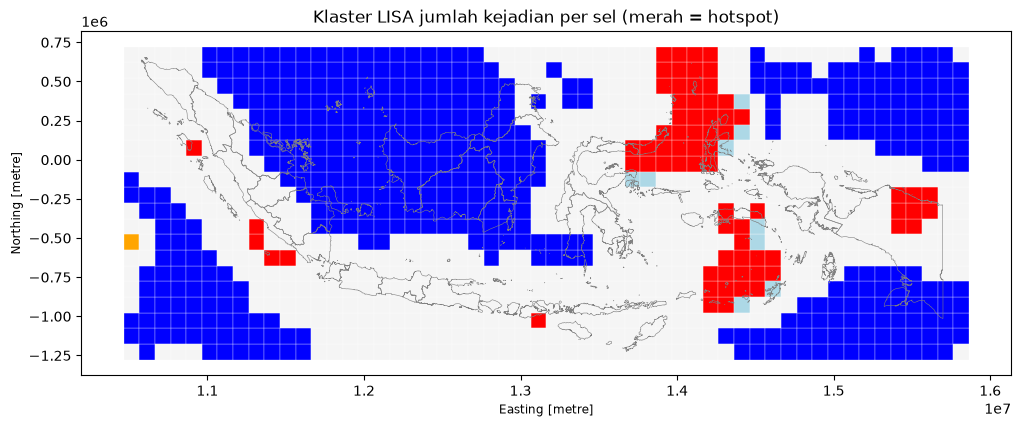

In [7]:
lisa = esda.Moran_Local(grid["count"], neighbors, permutations=999, seed=SEED)
QUADRANT_NAMES = {1: "HH hotspot", 2: "LH", 3: "LL coldspot", 4: "HL"}
grid["cluster"] = "tidak signifikan"
for number, name in QUADRANT_NAMES.items():
    is_this = (lisa.q == number) & (lisa.p_sim < ALPHA)
    grid.loc[is_this, "cluster"] = name
grid["lisa_i"] = lisa.Is
print(grid["cluster"].value_counts())

COLORS = {"HH hotspot": "red", "LH": "lightblue", "LL coldspot": "blue", "HL": "orange",
          "tidak signifikan": "whitesmoke"}
fig, ax = plt.subplots(figsize=(12, 5))
for name, part in grid.groupby("cluster"):
    part.plot(ax=ax, color=COLORS[name], edgecolor="white", linewidth=0.2)
regions.boundary.plot(ax=ax, color="gray", linewidth=0.4)
ax.set_title("Klaster LISA jumlah kejadian per sel (merah = hotspot)")
plt.show()

## Submission
Satu baris per sel grid: jumlah titik dan label klaster. Saat lomba, ikuti format soal.

In [8]:
submission = pd.DataFrame()
submission["cell_id"] = grid["cell_id"]
submission["count"] = grid["count"]
submission["cluster"] = grid["cluster"]
submission.to_csv("submission.csv", index=False)
submission.head()

,cell_id,count,cluster
0,0,0.0,tidak signifikan
1,1,0.0,LL coldspot
2,2,0.0,tidak signifikan
3,3,0.0,tidak signifikan
4,4,0.0,tidak signifikan
